# Telecom Customer Churn Prediction
**AIDS Department – PBL Project**

Team members & contributions: *(fill in: Name – Roll No – Contribution)*

---
## 1. Problem Definition & Business Understanding
**Problem statement:** A telecom company loses revenue every time a customer leaves (churns). Acquiring a new customer costs several times more than retaining one. We build a model that predicts which customers are likely to churn so the retention team can act early.

**Objectives**
1. Identify the key drivers of churn.
2. Build a classifier that detects at-risk customers with high recall.
3. Convert results into actionable retention strategies.

**Stakeholders:** Retention/marketing team, customer-support managers, finance, senior management.

**KPIs:** Churn rate (%), Recall & F1 on churners, ROC-AUC, estimated revenue saved by targeted retention.

**Why recall matters:** Missing a churner (false negative) loses the customer's lifetime revenue; wrongly contacting a loyal customer (false positive) costs only a small discount. So we prioritise recall/F1 over plain accuracy.

## 2. Dataset & Data Understanding
Source: IBM Telco Customer Churn sample dataset (also on Kaggle: *blastchar/telco-customer-churn*). 7,043 customers, 21 columns.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns, warnings
warnings.filterwarnings('ignore')
sns.set_style('whitegrid')

URL = 'https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv'
try:
    df = pd.read_csv(URL)
except Exception:
    df = pd.read_csv('Telco-Customer-Churn.csv')   # fallback: download from Kaggle and place beside notebook
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

### Data dictionary
| Column | Type | Description |
|---|---|---|
| customerID | ID | Unique customer id (dropped later) |
| gender, SeniorCitizen, Partner, Dependents | Demographic | Customer profile |
| tenure | Numeric | Months with the company |
| PhoneService, MultipleLines | Categorical | Phone services |
| InternetService | Categorical | DSL / Fiber optic / No |
| OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies | Categorical | Add-on services |
| Contract | Categorical | Month-to-month / One year / Two year |
| PaperlessBilling, PaymentMethod | Categorical | Billing details |
| MonthlyCharges, TotalCharges | Numeric | Current monthly bill, lifetime total |
| **Churn** | **Target** | Yes = customer left |

In [3]:
print('Duplicates:', df.duplicated().sum())
print('Missing (isnull):'); print(df.isnull().sum()[df.isnull().sum()>0])
# TotalCharges is stored as text because some values are blank spaces
print('Blank TotalCharges:', (df['TotalCharges'].str.strip()=='').sum())
df['Churn'].value_counts(normalize=True).mul(100).round(1)

Duplicates: 0
Missing (isnull):
Series([], dtype: int64)
Blank TotalCharges: 11


Churn
No     73.5
Yes    26.5
Name: proportion, dtype: float64

**Data quality findings:** No duplicates; `TotalCharges` has 11 blank values (all new customers with tenure = 0); target is imbalanced (~26.5% churn).

## 3. Data Preprocessing & Cleaning

In [4]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print(df[df['TotalCharges'].isnull()][['tenure','MonthlyCharges','TotalCharges']].head())
# Blank TotalCharges belong to tenure=0 customers who have not been billed yet -> set to 0
df['TotalCharges'] = df['TotalCharges'].fillna(0)

df = df.drop(columns='customerID')
df['Churn'] = df['Churn'].map({'No':0,'Yes':1})

# Collapse redundant categories ("No internet service"/"No phone service" == "No")
for c in df.select_dtypes('object').columns:
    df[c] = df[c].replace({'No internet service':'No','No phone service':'No'})

# Outlier check (IQR)
for c in ['tenure','MonthlyCharges','TotalCharges']:
    q1,q3 = df[c].quantile([.25,.75]); iqr=q3-q1
    n = ((df[c]<q1-1.5*iqr)|(df[c]>q3+1.5*iqr)).sum()
    print(f'{c}: {n} IQR outliers')

      tenure  MonthlyCharges  TotalCharges
488        0           52.55           NaN
753        0           20.25           NaN
936        0           80.85           NaN
1082       0           25.75           NaN
1340       0           56.05           NaN
tenure: 0 IQR outliers
MonthlyCharges: 0 IQR outliers
TotalCharges: 0 IQR outliers


No meaningful outliers were found, so none were removed. Encoding and scaling are done inside the model pipeline (Section 6) to prevent data leakage.

## 4. Exploratory Data Analysis (EDA)

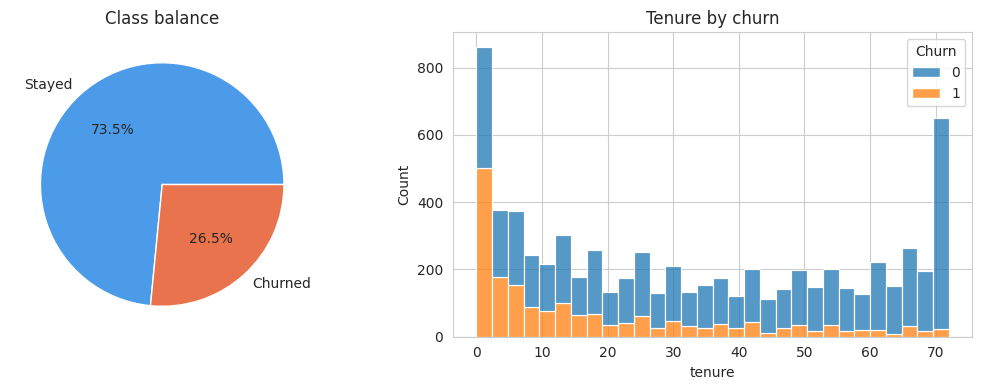

In [5]:
fig, ax = plt.subplots(1,2, figsize=(11,4))
df['Churn'].value_counts().plot.pie(autopct='%1.1f%%', labels=['Stayed','Churned'], ax=ax[0], colors=['#4c9be8','#e8734c'])
ax[0].set_ylabel(''); ax[0].set_title('Class balance')
sns.histplot(data=df, x='tenure', hue='Churn', bins=30, multiple='stack', ax=ax[1]); ax[1].set_title('Tenure by churn')
plt.tight_layout(); plt.show()

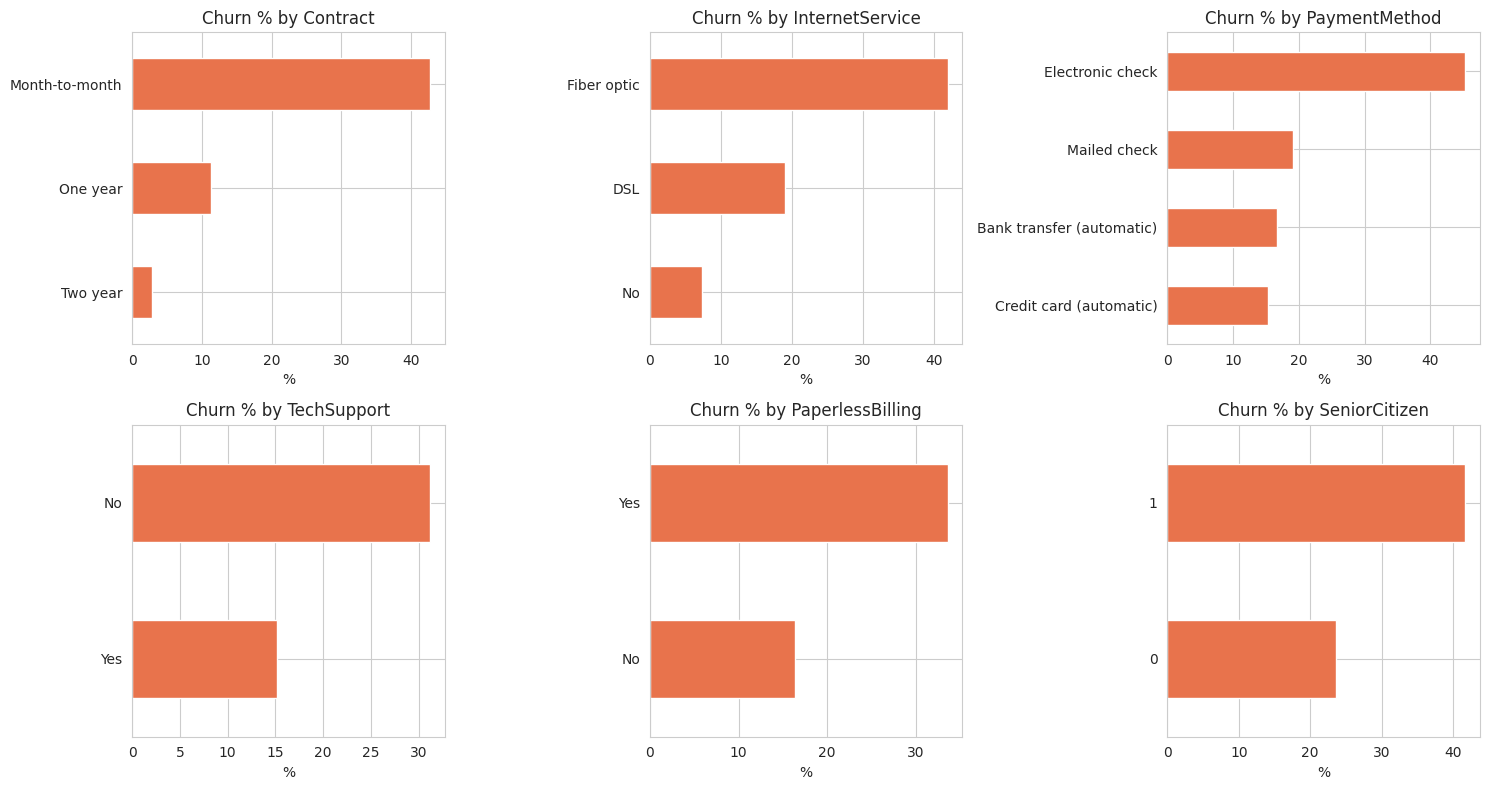

In [6]:
cols = ['Contract','InternetService','PaymentMethod','TechSupport','PaperlessBilling','SeniorCitizen']
fig, axes = plt.subplots(2,3, figsize=(15,8))
for a,c in zip(axes.ravel(), cols):
    (df.groupby(c)['Churn'].mean()*100).sort_values().plot.barh(ax=a, color='#e8734c')
    a.set_title(f'Churn % by {c}'); a.set_xlabel('%'); a.set_ylabel('')
plt.tight_layout(); plt.show()

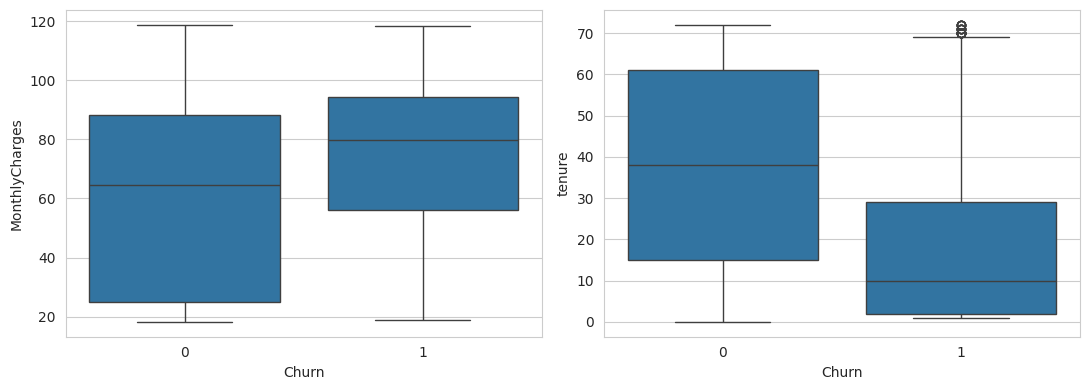

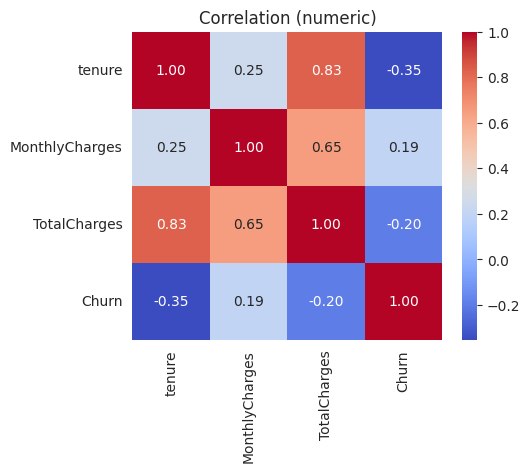

In [7]:
fig, ax = plt.subplots(1,2, figsize=(11,4))
sns.boxplot(data=df, x='Churn', y='MonthlyCharges', ax=ax[0])
sns.boxplot(data=df, x='Churn', y='tenure', ax=ax[1])
plt.tight_layout(); plt.show()

plt.figure(figsize=(5,4))
sns.heatmap(df[['tenure','MonthlyCharges','TotalCharges','Churn']].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation (numeric)'); plt.show()

In [8]:
# Statistical tests: chi-square for categorical, Mann-Whitney U for numeric
from scipy.stats import chi2_contingency, mannwhitneyu
rows=[]
for c in df.select_dtypes('object').columns:
    chi2,p,_,_ = chi2_contingency(pd.crosstab(df[c], df['Churn']))
    rows.append((c,'chi-square',round(chi2,1),p))
for c in ['tenure','MonthlyCharges','TotalCharges']:
    s,p = mannwhitneyu(df.loc[df.Churn==1,c], df.loc[df.Churn==0,c])
    rows.append((c,'Mann-Whitney',round(s),p))
tests = pd.DataFrame(rows, columns=['feature','test','statistic','p_value']).sort_values('p_value')
tests['significant(0.05)'] = tests.p_value<0.05
tests

,feature,test,statistic,p_value,significant(0.05)
12,Contract,chi-square,1184.6,5.863038e-258,True
15,tenure,Mann-Whitney,2515538.0,2.419636e-208,True
5,InternetService,chi-square,732.3,9.571788e-160,True
14,PaymentMethod,chi-square,648.1,3.682355e-140,True
17,TotalCharges,Mann-Whitney,3381224.0,5.685034e-83,True
13,PaperlessBilling,chi-square,258.3,4.073355e-58,True
16,MonthlyCharges,Mann-Whitney,6003126.0,3.311628e-54,True
6,OnlineSecurity,chi-square,205.6,1.232098e-46,True
9,TechSupport,chi-square,190.2,2.923567e-43,True
2,Dependents,chi-square,189.1,4.924922e-43,True


**EDA insights**
- Month-to-month contracts churn far more than 1- or 2-year contracts.
- Fiber-optic customers churn more than DSL customers (possible price/quality issue).
- Churners have much lower tenure: most leave in the first year.
- Customers without TechSupport / OnlineSecurity churn more; electronic-check payers churn most.
- Gender and PhoneService are not significant drivers.

## 5. Feature Engineering / Selection

In [9]:
df_fe = df.copy()
df_fe['tenure_group'] = pd.cut(df_fe.tenure, [-1,12,24,48,72], labels=['0-1yr','1-2yr','2-4yr','4-6yr']).astype(str)
addons = ['OnlineSecurity','OnlineBackup','DeviceProtection','TechSupport','StreamingTV','StreamingMovies']
df_fe['num_addons'] = (df_fe[addons]=='Yes').sum(axis=1)
df_fe['avg_monthly_spend'] = df_fe.TotalCharges / df_fe.tenure.replace(0,1)
df_fe['charge_gap'] = df_fe.MonthlyCharges - df_fe.avg_monthly_spend   # recent price rise indicator
df_fe['autopay'] = df_fe.PaymentMethod.str.contains('automatic').astype(int)

# Drop features with no statistical relationship to churn
df_fe = df_fe.drop(columns=['gender','PhoneService'])
df_fe.head()

,SeniorCitizen,Partner,Dependents,tenure,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,...,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,tenure_group,num_addons,avg_monthly_spend,charge_gap,autopay
0,0,Yes,No,1,No,DSL,No,Yes,No,No,...,Yes,Electronic check,29.85,29.85,0,0-1yr,1,29.850000,0.000000,0
1,0,No,No,34,No,DSL,Yes,No,Yes,No,...,No,Mailed check,56.95,1889.50,0,2-4yr,2,55.573529,1.376471,0
2,0,No,No,2,No,DSL,Yes,Yes,No,No,...,Yes,Mailed check,53.85,108.15,1,0-1yr,2,54.075000,-0.225000,0
3,0,No,No,45,No,DSL,Yes,No,Yes,Yes,...,No,Bank transfer (automatic),42.30,1840.75,0,2-4yr,3,40.905556,1.394444,1
4,0,No,No,2,No,Fiber optic,No,No,No,No,...,Yes,Electronic check,70.70,151.65,1,0-1yr,0,75.825000,-5.125000,0


**Justification**
- `tenure_group`, `num_addons`, `autopay`, `charge_gap` capture behaviour that EDA showed to matter.
- `gender` and `PhoneService` were statistically insignificant, so they were dropped.
- **Data-leakage handling:** the train/test split happens *before* any scaling/encoding, which is done inside a `Pipeline` fitted on training data only. `customerID` was removed. `TotalCharges` is kept because it is known at prediction time, but note it correlates with tenure x MonthlyCharges (multicollinearity does not hurt tree models; Logistic Regression is regularised).

## 6. Model Selection & Implementation

In [10]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.dummy import DummyClassifier

X, y = df_fe.drop(columns='Churn'), df_fe['Churn']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

num_cols = X.select_dtypes(include='number').columns.tolist()
cat_cols = X.select_dtypes(exclude='number').columns.tolist()
pre = ColumnTransformer([('num', StandardScaler(), num_cols),
                         ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols)])

models = {
 'Baseline (majority)': DummyClassifier(strategy='most_frequent'),
 'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced'),
 'Random Forest':       RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight='balanced', random_state=42),
 'Gradient Boosting':   GradientBoostingClassifier(random_state=42),
}
pipes = {n: Pipeline([('pre',pre),('clf',m)]) for n,m in models.items()}
print(len(X_train), 'train /', len(X_test), 'test rows;', len(num_cols), 'numeric,', len(cat_cols), 'categorical features')

5634 train / 1409 test rows; 8 numeric, 14 categorical features


**Why these models:** Dummy = sanity baseline; Logistic Regression = interpretable; Random Forest and Gradient Boosting = capture non-linear interactions on tabular data. `class_weight='balanced'` handles the 73/27 imbalance.

## 7. Model Evaluation & Validation

In [11]:
skf = StratifiedKFold(5, shuffle=True, random_state=42)
scoring = ['accuracy','precision','recall','f1','roc_auc']
rows=[]
for n,p in pipes.items():
    cv = cross_validate(p, X_train, y_train, cv=skf, scoring=scoring)
    rows.append({'model':n, **{m:cv[f'test_{m}'].mean().round(3) for m in scoring}})
cv_df = pd.DataFrame(rows).set_index('model'); cv_df

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Baseline (majority),0.735,0.000,0.000,0.000,0.500
Logistic Regression,0.749,0.518,0.799,0.628,0.846
Random Forest,0.781,0.571,0.696,0.627,0.843
Gradient Boosting,0.802,0.669,0.504,0.575,0.846


In [12]:
# Hyperparameter tuning of the best candidate (Gradient Boosting) with recall/F1 focus
from sklearn.model_selection import GridSearchCV
gs = GridSearchCV(pipes['Gradient Boosting'],
    {'clf__n_estimators':[100,200], 'clf__learning_rate':[0.05,0.1], 'clf__max_depth':[2,3]},
    cv=skf, scoring='roc_auc', n_jobs=-1).fit(X_train, y_train)
print('Best params:', gs.best_params_, '| CV AUC:', round(gs.best_score_,3))

Best params: {'clf__learning_rate': 0.05, 'clf__max_depth': 2, 'clf__n_estimators': 200} | CV AUC: 0.848


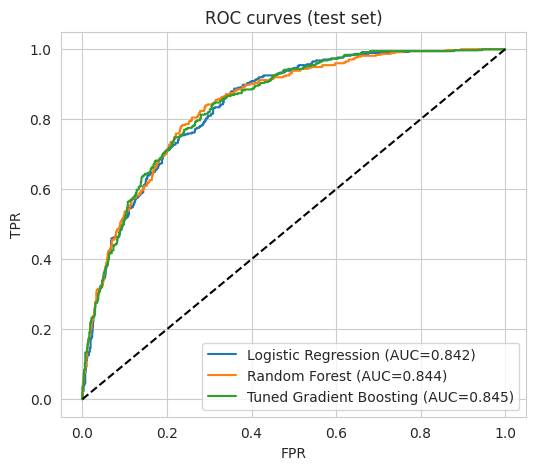

In [13]:
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, roc_auc_score, precision_recall_curve, f1_score)
final = {'Logistic Regression': pipes['Logistic Regression'].fit(X_train,y_train),
         'Random Forest': pipes['Random Forest'].fit(X_train,y_train),
         'Tuned Gradient Boosting': gs.best_estimator_}
plt.figure(figsize=(6,5))
for n,m in final.items():
    fpr,tpr,_ = roc_curve(y_test, m.predict_proba(X_test)[:,1])
    plt.plot(fpr,tpr,label=f'{n} (AUC={roc_auc_score(y_test,m.predict_proba(X_test)[:,1]):.3f})')
plt.plot([0,1],[0,1],'k--'); plt.xlabel('FPR'); plt.ylabel('TPR'); plt.legend(); plt.title('ROC curves (test set)'); plt.show()

Chosen threshold: 0.32
              precision    recall  f1-score   support

      Stayed       0.89      0.77      0.83      1035
     Churned       0.54      0.75      0.63       374

    accuracy                           0.77      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.77      0.78      1409



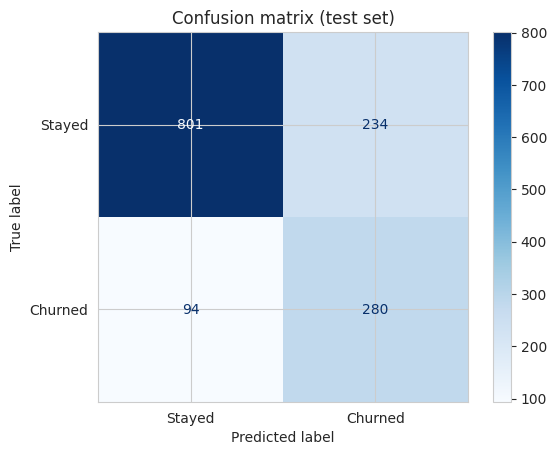

In [14]:
# Threshold tuning: pick the threshold that maximises F1 for churners on the training CV predictions
from sklearn.model_selection import cross_val_predict
best = gs.best_estimator_
oof = cross_val_predict(best, X_train, y_train, cv=skf, method='predict_proba')[:,1]
ths = np.arange(0.1,0.9,0.01)
th = ths[np.argmax([f1_score(y_train, oof>=t) for t in ths])]
print('Chosen threshold:', round(th,2))

proba = best.predict_proba(X_test)[:,1]; pred = (proba>=th).astype(int)
print(classification_report(y_test, pred, target_names=['Stayed','Churned']))
ConfusionMatrixDisplay(confusion_matrix(y_test,pred), display_labels=['Stayed','Churned']).plot(cmap='Blues')
plt.title('Confusion matrix (test set)'); plt.show()

**Interpretation:** Accuracy alone would be ~73% for a model that predicts "nobody churns", so we judge by recall, F1 and ROC-AUC. After threshold tuning the model catches a large share of real churners at the cost of some false alarms, a trade-off the business accepts because a retention offer costs far less than a lost customer. The test set was used only once, for final reporting.

### Model explainability

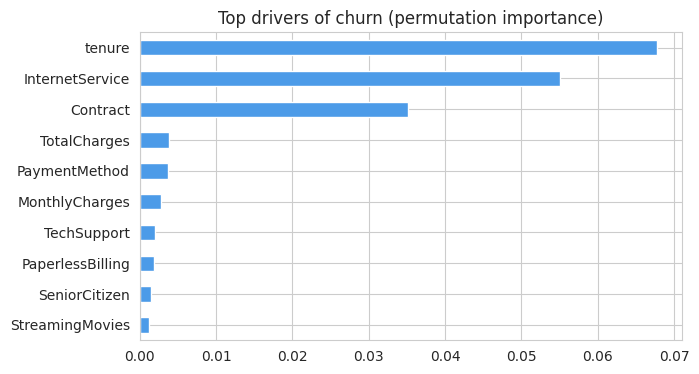

In [15]:
from sklearn.inspection import permutation_importance
r = permutation_importance(best, X_test, y_test, scoring='roc_auc', n_repeats=10, random_state=42, n_jobs=-1)
imp = pd.Series(r.importances_mean, index=X_test.columns).sort_values()
imp.tail(10).plot.barh(figsize=(7,4), color='#4c9be8'); plt.title('Top drivers of churn (permutation importance)'); plt.show()

## 8. Business Insights & Recommendations

In [16]:
# Revenue impact simulation (assumptions are editable)
avg_value = df.MonthlyCharges.mean()*12      # annual revenue per customer
offer_cost, success_rate = 50, 0.30          # cost per retention offer, % of contacted churners retained
tn,fp,fn,tp = confusion_matrix(y_test,pred).ravel()
saved = tp*success_rate*avg_value
cost  = (tp+fp)*offer_cost
print(f'Customers contacted: {tp+fp} | true churners reached: {tp}')
print(f'Revenue saved: {saved:,.0f} | Campaign cost: {cost:,.0f} | Net benefit: {saved-cost:,.0f}')
print(f'Without model (no action) all {tp+fn} churners lost = {(tp+fn)*avg_value:,.0f} revenue')

Customers contacted: 514 | true churners reached: 280
Revenue saved: 65,280 | Campaign cost: 25,700 | Net benefit: 39,580
Without model (no action) all 374 churners lost = 290,650 revenue


### Recommendations
1. **Push contract upgrades:** offer discounts to move month-to-month customers to 1-2 year plans (the biggest churn driver).
2. **Early-life onboarding:** run welcome calls and loyalty perks in the first 12 months, when most churn happens.
3. **Bundle TechSupport & OnlineSecurity:** free trials for customers without them; they churn far less.
4. **Review fiber-optic pricing/quality:** higher churn suggests a price-value or service problem.
5. **Promote autopay:** incentives for switching from electronic check to automatic payments.
6. **Operationalise the model:** score customers monthly and send the top-risk list to the retention team.

**Limitations & future work:** single snapshot (no time series), simulated business assumptions, no customer-satisfaction/complaint data; try SHAP, XGBoost/LightGBM, SMOTE, and a deployed Streamlit app.

## 9. Deployment & Documentation

In [17]:
import joblib
joblib.dump({'model': best, 'threshold': float(th)}, 'churn_model.pkl')
print('Saved churn_model.pkl')

Saved churn_model.pkl


Run `streamlit run app.py` (provided separately) for the live demo.

**Team contributions:** *(fill in)*